# PointPillars from scratch (KITTI 3D Object Detection)

Reimplementation of *PointPillars: Fast Encoders for Object Detection from Point Clouds* (Lang et al., CVPR 2019) in pure PyTorch — **no spconv, no CUDA extensions**, so it installs cleanly on Colab.

Pipeline: pillar voxelization -> PointNet pillar encoder -> scatter to pseudo-image -> 2D CNN backbone + FPN -> SSD anchor head (cls / box / direction).

Scope: `Car` class only (the standard starting point). Runtime: ~5 min/epoch on a T4 at batch 4.

**Runtime -> Change runtime type -> GPU before you start.**

In [1]:
import os
# os.environ["CUDA_LAUNCH_BLOCKING"] = "1"/
# Cell 1 - Environment
import torch
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
!pip -q install shapely

torch 2.11.0+cu130 | cuda: True
Tesla T4


## Cell 2 - Download KITTI

Velodyne is a ~29 GB zip (train+test); we only extract `training/`. Expect 20-40 min. Colab's disk must have ~60 GB free, so use a standard GPU runtime, not a tiny one.

If the download is too slow, skip the velodyne line and instead mount Drive with a copy you already have, or use a Kaggle KITTI mirror. Everything below only needs `training/{velodyne,label_2,calib}` and `ImageSets/{train,val}.txt`.

In [ ]:
# Cell 2 - KITTI download (run once)
!mkdir -p /content/kitti
%cd /content/kitti
B = "https://s3.eu-central-1.amazonaws.com/avg-kitti"
!wget -nc -q $B/data_object_calib.zip
!wget -nc -q $B/data_object_label_2.zip
!wget -nc    $B/data_object_velodyne.zip        # big one
!unzip -n -q data_object_calib.zip   'training/*'
!unzip -n -q data_object_label_2.zip 'training/*'
!unzip -n -q data_object_velodyne.zip 'training/*'
!rm -f data_object_velodyne.zip
!mkdir -p ImageSets
G = "https://raw.githubusercontent.com/open-mmlab/OpenPCDet/master/data/kitti/ImageSets"
!wget -nc -q -O ImageSets/train.txt $G/train.txt
!wget -nc -q -O ImageSets/val.txt   $G/val.txt
import os
print("velodyne scans:", len(os.listdir("training/velodyne")))
print("train/val ids :", sum(1 for _ in open("ImageSets/train.txt")), sum(1 for _ in open("ImageSets/val.txt")))

/content/kitti
--2026-10-11 05:48:47--  https://s3.eu-central-1.amazonaws.com/avg-kitti/data_object_velodyne.zip
Resolving s3.eu-central-1.amazonaws.com (s3.eu-central-1.amazonaws.com)... 52.219.75.203, 52.219.169.29, 52.219.169.137, ...
Connecting to s3.eu-central-1.amazonaws.com (s3.eu-central-1.amazonaws.com)|52.219.75.203|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 28750710812 (27G) [application/zip]
Saving to: ‘data_object_velodyne.zip’

data_object_velodyn 100%[===================>]  26.78G  20.3MB/s    in 22m 33s 

2026-10-11 06:11:21 (20.3 MB/s) - ‘data_object_velodyne.zip’ saved [28750710812/28750710812]

velodyne scans: 7481
train/val ids : 3712 3769


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Cell 3 - Config
import os, math, numpy as np, torch, torch.nn as nn, torch.nn.functional as F

CFG = dict(
    root          = "/content/kitti",
    pc_range      = [0, -39.68, -3, 69.12, 39.68, 1],   # xmin ymin zmin xmax ymax zmax (LiDAR frame)
    voxel_size    = [0.16, 0.16, 4],
    max_pts       = 32,        # points per pillar (N)
    max_pillars   = 12000,     # pillars per sample (P)
    cls_name      = "Car",
    anchor_size   = [3.9, 1.6, 1.56],   # dx, dy, dz
    anchor_bottom = -1.78,
    match_iou     = 0.60,
    unmatch_iou   = 0.45,
    dir_offset    = 0.78539,
)
CFG["nx"] = int(round((CFG["pc_range"][3] - CFG["pc_range"][0]) / CFG["voxel_size"][0]))  # 432
CFG["ny"] = int(round((CFG["pc_range"][4] - CFG["pc_range"][1]) / CFG["voxel_size"][1]))  # 496
CFG["fx"], CFG["fy"] = CFG["nx"] // 2, CFG["ny"] // 2   # anchor grid = backbone stride 2
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("grid", CFG["nx"], "x", CFG["ny"], "| anchor grid", CFG["fx"], "x", CFG["fy"])

grid 432 x 496 | anchor grid 216 x 248


In [3]:
# Cell 4 - KITTI IO: calib, labels (camera -> LiDAR), FOV filter, pillarization

def read_calib(p):
    d = {}
    for line in open(p):
        if ":" not in line: continue
        k, v = line.split(":", 1)
        d[k] = np.array([float(x) for x in v.split()], np.float32)
    P2 = d["P2"].reshape(3, 4)
    R0 = np.eye(4, dtype=np.float32); R0[:3, :3] = d["R0_rect"].reshape(3, 3)
    V2C = np.eye(4, dtype=np.float32); V2C[:3, :4] = d["Tr_velo_to_cam"].reshape(3, 4)
    return P2, R0, V2C

def cam_to_lidar(pts, R0, V2C):
    p = np.hstack([pts, np.ones((len(pts), 1), np.float32)])
    return (np.linalg.inv(V2C) @ np.linalg.inv(R0) @ p.T).T[:, :3]

def fov_filter(pts, P2, R0, V2C, img=(375, 1242)):
    # labels only exist inside the left-camera frustum, so drop everything else
    p = np.hstack([pts[:, :3], np.ones((len(pts), 1), np.float32)])
    cam = (R0 @ V2C @ p.T).T
    uv = (P2 @ cam.T).T
    uv = uv[:, :2] / np.clip(uv[:, 2:3], 1e-6, None)
    m = (cam[:, 2] > 0) & (uv[:, 0] >= 0) & (uv[:, 0] < img[1]) & (uv[:, 1] >= 0) & (uv[:, 1] < img[0])
    return pts[m]

def read_label(p, cls, R0, V2C):
    loc, dim, ry = [], [], []
    for line in open(p):
        f = line.split()
        if f[0] != cls: continue
        h, w, l = float(f[8]), float(f[9]), float(f[10])
        dim.append([l, w, h])                                   # -> dx, dy, dz
        loc.append([float(f[11]), float(f[12]), float(f[13])])  # camera frame, bottom-center
        ry.append(float(f[14]))
    if not loc: return np.zeros((0, 7), np.float32)
    loc = cam_to_lidar(np.array(loc, np.float32), R0, V2C)
    dim = np.array(dim, np.float32); ry = np.array(ry, np.float32)
    loc[:, 2] += dim[:, 2] / 2                                  # bottom-center -> center
    heading = -(ry + np.pi / 2)                                 # camera ry -> LiDAR yaw
    return np.concatenate([loc, dim, heading[:, None]], 1).astype(np.float32)

def pillarize(points, cfg):
    pr, vs = cfg["pc_range"], cfg["voxel_size"]
    m = ((points[:, 0] >= pr[0]) & (points[:, 0] < pr[3]) &
         (points[:, 1] >= pr[1]) & (points[:, 1] < pr[4]) &
         (points[:, 2] >= pr[2]) & (points[:, 2] < pr[5]))
    points = points[m]
    N, P = cfg["max_pts"], cfg["max_pillars"]
    if len(points) == 0:
        return np.zeros((1, N, 4), np.float32), np.zeros((1, 2), np.int32), np.ones(1, np.int32)

    coords = np.floor((points[:, :2] - np.array(pr[:2], np.float32)) / np.array(vs[:2], np.float32)).astype(np.int32)
    coords = np.clip(coords, 0, [cfg["nx"] - 1, cfg["ny"] - 1]).astype(np.int32)
    key = coords[:, 1] * cfg["nx"] + coords[:, 0]

    o = np.argsort(key, kind="stable")
    points, coords, key = points[o], coords[o], key[o]
    uk, start, cnt = np.unique(key, return_index=True, return_counts=True)
    npil = len(uk)
    idx_in = np.arange(len(points)) - np.repeat(start, cnt)
    pid = np.repeat(np.arange(npil), cnt)
    v = idx_in < N
    feat = np.zeros((npil, N, 4), np.float32)
    feat[pid[v], idx_in[v]] = points[v, :4]
    coo = coords[start]
    num = np.minimum(cnt, N).astype(np.int32)
    if npil > P:
        sel = np.random.choice(npil, P, replace=False)
        feat, coo, num = feat[sel], coo[sel], num[sel]
    return feat, coo, num

In [4]:
# Cell 5 - Dataset + augmentation

def augment(pts, boxes):
    if np.random.rand() < 0.5:                       # flip about the x axis
        pts[:, 1] *= -1; boxes[:, 1] *= -1; boxes[:, 6] *= -1
    a = np.random.uniform(-np.pi / 4, np.pi / 4)     # global rotation
    c, s = np.cos(a), np.sin(a)
    R = np.array([[c, -s], [s, c]], np.float32)
    pts[:, :2] = pts[:, :2] @ R.T
    if len(boxes):
        boxes[:, :2] = boxes[:, :2] @ R.T; boxes[:, 6] += a
    k = np.random.uniform(0.95, 1.05)                # global scale
    pts[:, :3] *= k
    if len(boxes): boxes[:, :6] *= k
    return pts, boxes

class KittiPillars(torch.utils.data.Dataset):
    def __init__(self, cfg, split="train", train=True, limit=None):
        self.cfg, self.train = cfg, train
        self.dir = cfg["root"] + "/training"
        ids = [l.strip() for l in open(f"{cfg['root']}/ImageSets/{split}.txt") if l.strip()]
        have = {f[:-4] for f in os.listdir(self.dir + "/velodyne")}
        self.ids = [i for i in ids if i in have][:limit]

    def __len__(self): return len(self.ids)

    def load(self, k):
        i = self.ids[k]
        pts = np.fromfile(f"{self.dir}/velodyne/{i}.bin", np.float32).reshape(-1, 4).copy()
        P2, R0, V2C = read_calib(f"{self.dir}/calib/{i}.txt")
        pts = fov_filter(pts, P2, R0, V2C)
        gt = read_label(f"{self.dir}/label_2/{i}.txt", self.cfg["cls_name"], R0, V2C)
        return pts, gt, i

    def __getitem__(self, k):
        pts, gt, fid = self.load(k)
        if self.train: pts, gt = augment(pts, gt)
        f, c, n = pillarize(pts, self.cfg)
        return dict(pillars=f, coords=c, num=n, gt=gt, fid=fid)

def collate(batch):
    coo = [np.pad(b["coords"], ((0, 0), (1, 0)), constant_values=i) for i, b in enumerate(batch)]
    return dict(
        pillars = torch.from_numpy(np.concatenate([b["pillars"] for b in batch])),
        coords  = torch.from_numpy(np.concatenate(coo)).long(),
        num     = torch.from_numpy(np.concatenate([b["num"] for b in batch])).long(),
        gt      = [torch.from_numpy(b["gt"]).float() for b in batch],
        fid     = [b["fid"] for b in batch],
        bs      = len(batch),
    )

def to_dev(b):
    for k in ("pillars", "coords", "num"): b[k] = b[k].to(DEV, non_blocking=True)
    return b

ds_tr = KittiPillars(CFG, "train", True)
ds_va = KittiPillars(CFG, "val",  False)
print(len(ds_tr), "train /", len(ds_va), "val")
s = ds_tr[0]
print("pillars", s["pillars"].shape, "coords", s["coords"].shape, "gt", s["gt"].shape)

3712 train / 3769 val
pillars (3664, 32, 4) coords (3664, 2) gt (0, 7)


In [5]:
# Cell 6 - Anchors, box coder, target assignment

def make_anchors(cfg):
    pr, vs = cfg["pc_range"], cfg["voxel_size"]
    sx, sy = vs[0] * 2, vs[1] * 2
    x = pr[0] + (torch.arange(cfg["fx"]) + 0.5) * sx
    y = pr[1] + (torch.arange(cfg["fy"]) + 0.5) * sy
    dx, dy, dz = cfg["anchor_size"]
    z = cfg["anchor_bottom"] + dz / 2
    yy, xx = torch.meshgrid(y, x, indexing="ij")
    out = []
    for r in (0.0, np.pi / 2):
        out.append(torch.stack([xx, yy, torch.full_like(xx, z), torch.full_like(xx, dx),
                                torch.full_like(xx, dy), torch.full_like(xx, dz),
                                torch.full_like(xx, r)], -1))
    return torch.stack(out, 2).reshape(-1, 7)        # (fy*fx*2, 7), order matches head output

def limit_period(v, offset=0.5, period=np.pi):
    return v - torch.floor(v / period + offset) * period

def encode(g, a):
    d = torch.sqrt(a[:, 3] ** 2 + a[:, 4] ** 2)
    return torch.stack([(g[:, 0] - a[:, 0]) / d, (g[:, 1] - a[:, 1]) / d, (g[:, 2] - a[:, 2]) / a[:, 5],
                        torch.log(g[:, 3] / a[:, 3]), torch.log(g[:, 4] / a[:, 4]),
                        torch.log(g[:, 5] / a[:, 5]), g[:, 6] - a[:, 6]], -1)

def decode(p, a):
    d = torch.sqrt(a[:, 3] ** 2 + a[:, 4] ** 2)
    return torch.stack([p[:, 0] * d + a[:, 0], p[:, 1] * d + a[:, 1], p[:, 2] * a[:, 5] + a[:, 2],
                        torch.exp(p[:, 3]) * a[:, 3], torch.exp(p[:, 4]) * a[:, 4],
                        torch.exp(p[:, 5]) * a[:, 5], p[:, 6] + a[:, 6]], -1)

def bev_aabb(b):            # axis-aligned hull of the rotated BEV box (fast, good enough for matching)
    c, s = torch.cos(b[:, 6]).abs(), torch.sin(b[:, 6]).abs()
    ex = (b[:, 3] * c + b[:, 4] * s) / 2
    ey = (b[:, 3] * s + b[:, 4] * c) / 2
    return torch.stack([b[:, 0] - ex, b[:, 1] - ey, b[:, 0] + ex, b[:, 1] + ey], -1)

def iou_aabb(a, b):
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    lt = torch.max(a[:, None, :2], b[None, :, :2])
    rb = torch.min(a[:, None, 2:], b[None, :, 2:])
    wh = (rb - lt).clamp(min=0)
    inter = wh[..., 0] * wh[..., 1]
    return inter / (area_a[:, None] + area_b[None] - inter + 1e-9)

def assign(anchors, gt, cfg):
    K = anchors.shape[0]
    labels = torch.full((K,), -1, dtype=torch.long, device=anchors.device)
    reg = torch.zeros(K, 7, device=anchors.device)
    dirc = torch.zeros(K, dtype=torch.long, device=anchors.device)
    if len(gt) == 0:
        labels[:] = 0
        return labels, reg, dirc
    iou = iou_aabb(bev_aabb(anchors), bev_aabb(gt))              # K x G
    mx, arg = iou.max(1)
    labels[mx < cfg["unmatch_iou"]] = 0
    pos = mx >= cfg["match_iou"]
    gmax, gidx = iou.max(0)                                      # force-match best anchor per GT
    keep = gmax > 0.1
    pos[gidx[keep]] = True
    arg[gidx[keep]] = torch.arange(len(gt), device=gt.device)[keep]
    labels[pos] = 1
    if pos.any():
        g = gt[arg[pos]]
        reg[pos] = encode(g, anchors[pos])
        dirc[pos] = (limit_period(g[:, 6] - cfg["dir_offset"], 0.0, 2 * np.pi) > np.pi).long()
    return labels, reg, dirc

ANCHORS = make_anchors(CFG).to(DEV)
print("anchors:", ANCHORS.shape)

anchors: torch.Size([107136, 7])


In [6]:
# Cell 7 - Pillar Feature Net + scatter to pseudo-image

class PFN(nn.Module):
    def __init__(self, cfg, out=64):
        super().__init__()
        self.cfg = cfg
        self.lin = nn.Linear(9, out, bias=False)
        self.bn = nn.BatchNorm1d(out, eps=1e-3, momentum=0.01)

    def forward(self, p, c, n):                    # p (M,N,4)  c (M,3)=[b,x,y]  n (M,)
        pr, vs = self.cfg["pc_range"], self.cfg["voxel_size"]
        N = p.shape[1]
        mask = (torch.arange(N, device=p.device)[None] < n[:, None]).unsqueeze(-1).to(p.dtype)
        mean = (p[..., :3] * mask).sum(1, keepdim=True) / n.clamp(min=1)[:, None, None]
        f_cluster = p[..., :3] - mean                                   # offset to pillar centroid
        cx = (c[:, 1].to(p.dtype) + 0.5) * vs[0] + pr[0]
        cy = (c[:, 2].to(p.dtype) + 0.5) * vs[1] + pr[1]
        f_center = torch.stack([p[..., 0] - cx[:, None], p[..., 1] - cy[:, None]], -1)
        f = torch.cat([p, f_cluster, f_center], -1) * mask              # D = 9
        f = self.lin(f)
        f = F.relu(self.bn(f.transpose(1, 2)).transpose(1, 2)) * mask
        return f.max(1)[0]                                              # (M, 64)

def scatter(feats, coords, bs, cfg):
    C = feats.shape[1]
    canvas = feats.new_zeros(bs, C, cfg["ny"] * cfg["nx"])
    idx = (coords[:, 2] * cfg["nx"] + coords[:, 1]).clamp_(0, cfg["ny"] * cfg["nx"] - 1)
    canvas[coords[:, 0], :, idx] = feats
    return canvas.view(bs, C, cfg["ny"], cfg["nx"])

In [7]:
# Cell 8 - 2D CNN backbone + upsampling neck + SSD head

def cbr(i, o, k=3, s=1, p=1):
    return nn.Sequential(nn.Conv2d(i, o, k, s, p, bias=False),
                         nn.BatchNorm2d(o, eps=1e-3, momentum=0.01),
                         nn.ReLU(inplace=True))

class Backbone(nn.Module):
    def __init__(self, inc=64):
        super().__init__()
        blocks = [(inc, 64, 4, 2), (64, 128, 6, 2), (128, 256, 6, 2)]
        ups    = [(64, 128, 1), (128, 128, 2), (256, 128, 4)]
        self.blocks = nn.ModuleList(nn.Sequential(cbr(i, o, 3, s, 1), *[cbr(o, o) for _ in range(n - 1)])
                                    for i, o, n, s in blocks)
        self.ups = nn.ModuleList(nn.Sequential(nn.ConvTranspose2d(i, o, s, s, bias=False),
                                               nn.BatchNorm2d(o, eps=1e-3, momentum=0.01),
                                               nn.ReLU(inplace=True)) for i, o, s in ups)
    def forward(self, x):
        outs = []
        for b, u in zip(self.blocks, self.ups):
            x = b(x); outs.append(u(x))
        return torch.cat(outs, 1)                     # (B, 384, fy, fx)

class Head(nn.Module):
    def __init__(self, inc=384, na=2, nc=1):
        super().__init__()
        self.na, self.nc = na, nc
        self.cls = nn.Conv2d(inc, na * nc, 1)
        self.box = nn.Conv2d(inc, na * 7, 1)
        self.dir = nn.Conv2d(inc, na * 2, 1)
        nn.init.constant_(self.cls.bias, -math.log((1 - 0.01) / 0.01))   # focal-loss prior
    def forward(self, x):
        B = x.shape[0]
        f = lambda t, d: t.permute(0, 2, 3, 1).reshape(B, -1, d)
        return f(self.cls(x), self.nc), f(self.box(x), 7), f(self.dir(x), 2)

class PointPillars(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.pfn = PFN(cfg, 64)
        self.backbone = Backbone(64)
        self.head = Head(384)
    def forward(self, b):
        f = self.pfn(b["pillars"], b["coords"], b["num"])
        x = scatter(f, b["coords"], b["bs"], self.cfg)
        return self.head(self.backbone(x))

model = PointPillars(CFG).to(DEV)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M params")

4.814804 M params


In [8]:
# Cell 9 - Losses (focal + smooth-L1 with sine-difference + direction CE)

def focal(pred, tgt, alpha=0.25, gamma=2.0):
    p = torch.sigmoid(pred)
    pt = tgt * p + (1 - tgt) * (1 - p)
    w = alpha * tgt + (1 - alpha) * (1 - tgt)
    ce = F.binary_cross_entropy_with_logits(pred, tgt, reduction="none")
    return w * (1 - pt).pow(gamma) * ce

def smooth_l1(d, beta=1 / 9):
    a = d.abs()
    return torch.where(a < beta, 0.5 * a * a / beta, a - 0.5 * beta)

def sin_diff(p, g):
    rp = torch.sin(p[..., 6:7]) * torch.cos(g[..., 6:7])
    rg = torch.cos(p[..., 6:7]) * torch.sin(g[..., 6:7])
    return torch.cat([p[..., :6], rp], -1), torch.cat([g[..., :6], rg], -1)

def compute_loss(preds, batch, anchors, cfg):
    cls_p, box_p, dir_p = preds
    L, R, D = [], [], []
    for g in batch["gt"]:
        l, r, d = assign(anchors, g.to(anchors.device), cfg)
        L.append(l); R.append(r); D.append(d)
    labels = torch.stack(L); reg_t = torch.stack(R); dir_t = torch.stack(D)

    pos = labels == 1
    cared = labels >= 0
    npos = pos.sum().clamp(min=1).float()

    cls_t = pos.unsqueeze(-1).to(cls_p.dtype)
    l_cls = (focal(cls_p, cls_t).squeeze(-1) * cared).sum() / npos

    pb, gb = sin_diff(box_p[pos], reg_t[pos])
    l_box = smooth_l1(pb - gb).sum() / npos * 2.0

    l_dir = F.cross_entropy(dir_p[pos], dir_t[pos], reduction="sum") / npos * 0.2 \
            if pos.any() else box_p.sum() * 0
    return l_cls + l_box + l_dir, dict(cls=l_cls.item(), box=l_box.item(),
                                       dir=float(l_dir), npos=int(npos))

In [9]:
# Cell 10 - Train
from torch.utils.data import DataLoader
import time

EPOCHS, BS = 20, 8
dl_tr = DataLoader(ds_tr, BS, shuffle=True, num_workers=4, collate_fn=collate,
                   pin_memory=True, drop_last=True, persistent_workers=True)

opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.01, betas=(0.95, 0.99))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=EPOCHS * len(dl_tr),
                                            pct_start=0.4, div_factor=10, final_div_factor=1e4)
scaler = torch.amp.GradScaler("cuda")

for ep in range(EPOCHS):
    model.train(); t0 = time.time(); run = 0.0
    for it, b in enumerate(dl_tr):
        b = to_dev(b)
        with torch.amp.autocast("cuda"):
            preds = model(b)
        preds = [p.float() for p in preds]
        loss, parts = compute_loss(preds, b, ANCHORS, CFG)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        scaler.step(opt); scaler.update(); sched.step()
        run += loss.item()
        if it % 100 == 0:
            print(f"ep{ep} it{it}/{len(dl_tr)} loss {loss.item():.3f} "
                  f"cls {parts['cls']:.3f} box {parts['box']:.3f} pos {parts['npos']}")
    print(f"== epoch {ep} mean {run/len(dl_tr):.3f}  ({time.time()-t0:.0f}s)")
    torch.save(model.state_dict(), "/content/pointpillars.pth")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_51697/170873921.py:40: User

ep0 it0/464 loss 8.390 cls 1.629 box 6.631 pos 43
ep0 it100/464 loss 1.797 cls 0.874 box 0.791 pos 52
ep0 it200/464 loss 2.026 cls 0.937 box 0.943 pos 89
ep0 it300/464 loss 1.533 cls 0.797 box 0.616 pos 68
ep0 it400/464 loss 1.419 cls 0.685 box 0.615 pos 121
== epoch 0 mean 2.119  (173s)
ep1 it0/464 loss 1.593 cls 0.689 box 0.780 pos 48
ep1 it100/464 loss 1.133 cls 0.446 box 0.573 pos 181
ep1 it200/464 loss 1.060 cls 0.378 box 0.581 pos 99
ep1 it300/464 loss 1.032 cls 0.405 box 0.522 pos 104
ep1 it400/464 loss 1.147 cls 0.518 box 0.545 pos 113
== epoch 1 mean 1.439  (168s)
ep2 it0/464 loss 1.421 cls 0.508 box 0.734 pos 113
ep2 it100/464 loss 1.877 cls 0.917 box 0.849 pos 23
ep2 it200/464 loss 1.053 cls 0.364 box 0.588 pos 128
ep2 it300/464 loss 1.173 cls 0.433 box 0.639 pos 54
ep2 it400/464 loss 1.287 cls 0.523 box 0.651 pos 109
== epoch 2 mean 1.240  (169s)
ep3 it0/464 loss 0.940 cls 0.298 box 0.548 pos 158
ep3 it100/464 loss 1.794 cls 0.644 box 1.043 pos 39
ep3 it200/464 loss 0.909 c

In [10]:
# Cell 11 - Inference: decode + rotated BEV NMS
from shapely.geometry import Polygon

def corners_bev(b):
    x, y, dx, dy, r = b[0], b[1], b[3], b[4], b[6]
    c, s = np.cos(r), np.sin(r)
    p = np.array([[dx / 2, dy / 2], [dx / 2, -dy / 2], [-dx / 2, -dy / 2], [-dx / 2, dy / 2]])
    return p @ np.array([[c, -s], [s, c]]).T + np.array([x, y])

def iou_bev_rot(a, b):
    pa, pb = Polygon(corners_bev(a)), Polygon(corners_bev(b))
    if not (pa.is_valid and pb.is_valid): return 0.0
    i = pa.intersection(pb).area
    return i / (pa.area + pb.area - i + 1e-9)

def nms_bev(boxes, scores, thr=0.1, topk=100, pre=500):
    order = np.argsort(-scores)[:pre]; keep = []
    for i in order:
        if all(iou_bev_rot(boxes[i], boxes[j]) <= thr for j in keep):
            keep.append(i)
            if len(keep) >= topk: break
    return keep

@torch.no_grad()
def predict(model, batch, anchors, cfg, score_thr=0.3):
    model.eval()
    cls_p, box_p, dir_p = model(to_dev(batch))
    scores = torch.sigmoid(cls_p).squeeze(-1)          # (B, K)
    outs = []
    for b in range(batch["bs"]):
        m = scores[b] > score_thr
        if m.sum() == 0:
            outs.append(np.zeros((0, 8), np.float32)); continue
        boxes = decode(box_p[b][m].float(), anchors[m])
        dcls = dir_p[b][m].argmax(-1).float()
        per = np.pi
        val = limit_period(boxes[:, 6] - cfg["dir_offset"], 0.5, per)
        boxes[:, 6] = val + cfg["dir_offset"] + per * dcls
        bx = boxes.cpu().numpy(); sc = scores[b][m].cpu().numpy()
        k = nms_bev(bx, sc)
        outs.append(np.concatenate([bx[k], sc[k][:, None]], 1).astype(np.float32))
    return outs

In [11]:
# Cell 12 - Evaluate on the val split (BEV AP@0.7, 40-point interpolation)

def ap_r40(dets, gts, iou_thr=0.7):
    npos = sum(len(g) for g in gts)
    flat = [(d[7], fi, d[:7]) for fi, D in enumerate(dets) for d in D]
    flat.sort(key=lambda x: -x[0])
    matched = [np.zeros(len(g), bool) for g in gts]
    tp = np.zeros(len(flat)); fp = np.zeros(len(flat))
    for k, (_, fi, b) in enumerate(flat):
        g = gts[fi]
        if len(g) == 0: fp[k] = 1; continue
        ious = np.array([iou_bev_rot(b, gg) for gg in g])
        j = int(ious.argmax())
        if ious[j] >= iou_thr and not matched[fi][j]: tp[k] = 1; matched[fi][j] = True
        else: fp[k] = 1
    tp, fp = np.cumsum(tp), np.cumsum(fp)
    rec = tp / max(npos, 1); prec = tp / np.maximum(tp + fp, 1e-9)
    return sum((prec[rec >= r].max() if (rec >= r).any() else 0.0)
               for r in np.linspace(1 / 40, 1, 40)) / 40

model.load_state_dict(torch.load("/content/pointpillars.pth", map_location=DEV))
dl_va = DataLoader(ds_va, 4, shuffle=False, num_workers=4, collate_fn=collate)
dets, gts = [], []
for b in dl_va:
    gts += [g.numpy() for g in b["gt"]]
    dets += predict(model, b, ANCHORS, CFG)
print("Car BEV AP@0.7 :", round(ap_r40(dets, gts, 0.7) * 100, 2))
print("Car BEV AP@0.5 :", round(ap_r40(dets, gts, 0.5) * 100, 2))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Car BEV AP@0.7 : 72.13
Car BEV AP@0.5 : 80.78


This is a simplified single-class AP over the whole val split — it ignores KITTI's easy/moderate/hard difficulty buckets and its `DontCare` handling, so numbers won't line up exactly with the leaderboard. For official numbers, run the KITTI devkit evaluator or OpenPCDet's `kitti_object_eval_python` on your dumped predictions.

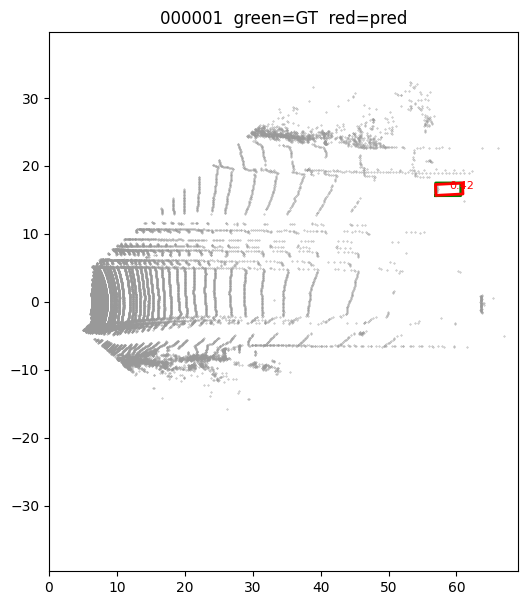

In [12]:
# Cell 13 - Visualize one frame in BEV
import matplotlib.pyplot as plt

def draw(idx=0, score_thr=0.4):
    pts, gt, fid = ds_va.load(idx)
    s = ds_va[idx]
    b = collate([s]); det = predict(model, b, ANCHORS, CFG, score_thr)[0]
    pr = CFG["pc_range"]
    plt.figure(figsize=(12, 7))
    plt.scatter(pts[:, 0], pts[:, 1], s=0.1, c="0.6")
    for g in gt:
        c = np.vstack([corners_bev(g), corners_bev(g)[:1]])
        plt.plot(c[:, 0], c[:, 1], "g-", lw=2)
    for d in det:
        c = np.vstack([corners_bev(d), corners_bev(d)[:1]])
        plt.plot(c[:, 0], c[:, 1], "r-", lw=2)
        plt.text(d[0], d[1], f"{d[7]:.2f}", color="r", fontsize=8)
    plt.xlim(pr[0], pr[3]); plt.ylim(pr[1], pr[4]); plt.gca().set_aspect("equal")
    plt.title(f"{fid}  green=GT  red=pred"); plt.show()

draw(0)

## Where to go next

- **GT-database sampling** (paste cropped GT cars from other frames into each scene) is the single biggest accuracy win left — worth ~5-8 AP. Build a `.pkl` of cropped car points once, then paste 15 per scene with collision checks.
- **Rotated IoU for anchor matching** instead of the axis-aligned hull used in Cell 6.
- **More classes**: add Pedestrian/Cyclist anchor sizes and widen the head to `na = 6`.
- **Compare against OpenPCDet** (SECOND, PV-RCNN, CenterPoint) once this baseline trains: `git clone https://github.com/open-mmlab/OpenPCDet`, install `spconv-cu121` matching the Colab CUDA, and point its KITTI path at `/content/kitti`.